# eBay-style Marketplace Analytics with Apache Spark — FA2, Big Data Analytics

**Group members:** [add names]

## Context
Our FA1 case study was **eBay** (Hadoop/HDFS/NoSQL architecture for a large online marketplace).
eBay does not publish its transaction data, so for FA2 we use the **Olist Brazilian e-commerce marketplace dataset**
(2016-2018, about 100k orders, 9 linked tables): independent sellers sell to buyers through one platform, which is the
same marketplace model as eBay. It is a **public stand-in**, not eBay data.

## Problem statement
A marketplace grows by knowing **when** and **where** demand happens and **how well it is fulfilled**.
Using Apache Spark (PySpark, local mode) we answer six questions:

| # | Question | Spark work | Visualization |
|---|---|---|---|
| Q1 | How did orders and revenue grow month by month? | join, groupBy month, window `lag` for MoM growth | **Time-series line (advanced)** |
| Q2 | Which weekdays and hours do buyers purchase most? | `date_format`/`hour`, groupBy, `pivot` | **Heatmap (advanced)** |
| Q3 | Where are buyers and revenue concentrated? | aggregate 1M geolocation rows per zip prefix, join customers | **Geospatial map (advanced)** |
| Q4 | Do late deliveries lower review scores? | `datediff`, late flag, join reviews | Bar charts |
| Q5 | Which seller states ship to which buyer states? | 4-table join, groupBy (seller_state, customer_state) | **Network graph (advanced)** |
| Q6 | Which product categories earn the most? | join translation, groupBy, `rank` window | Horizontal bar |

## Table of contents
1. Spark setup
2. Data ingestion (explicit schemas)
3. Cleaning and feature engineering (lazy evaluation, cache, Parquet)
4. Spark SQL
5. Q1 Monthly growth (advanced: time series)
6. Q2 Weekday x hour demand (advanced: heatmap)
7. Q3 Geography of buyers (advanced: geospatial)
8. Q4 Late delivery and reviews
9. Q5 Seller-state to buyer-state flows (advanced: network graph)
10. Q6 Top product categories
11. RDD vs DataFrame
12. Insights and Recommendations
13. Spark concepts used
14. Limitations and References

## 1. Spark setup
`SparkSession` is the entry point of a Spark application. We start it in **local mode with 4 cores**.

In [1]:
import sys, warnings, time
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "common.py").exists())   # .../fa2
sys.path.insert(0, str(ROOT / "src"))
import common

NB_T0 = time.time()
spark = common.get_spark("fa2-notebook", cores=4, memory="3g")
spark.sparkContext.setLogLevel("ERROR")

print("Spark version      :", spark.version)
print("Master             :", spark.sparkContext.master)
print("defaultParallelism :", spark.sparkContext.defaultParallelism)
print("Session time zone  :", spark.conf.get("spark.sql.session.timeZone"))

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/15 12:53:10 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version      : 4.2.0
Master             : local[4]
defaultParallelism : 4
Session time zone  : America/Sao_Paulo


`local[4]` means the **driver and the executors all run inside one JVM on this machine, using 4 cores** (4 tasks can run in parallel).
On a real cluster (like eBay's Hadoop/YARN) the same code would run unchanged with executors spread over many machines.

## 2. Data ingestion
We read the raw Olist CSVs with **explicit schemas** (`StructType`) instead of `inferSchema`: it is faster (no extra pass over the data)
and keeps zip prefixes as strings so `01037` does not lose its leading zero. Review comments contain line breaks and quotes,
hence `multiLine` and `escape`.

In [2]:
from pyspark.sql import functions as F
from pyspark.sql import Window
from pyspark.sql.types import (StructType, StructField, StringType, IntegerType,
                               DoubleType, TimestampType)
import pandas as pd
from IPython.display import display, Markdown

def S(name, typ=StringType()):
    return StructField(name, typ, True)          # nullable field shorthand
I, D, TS = IntegerType(), DoubleType(), TimestampType()

SCHEMAS = {
    "olist_orders_dataset": StructType([
        S("order_id"), S("customer_id"), S("order_status"),
        S("order_purchase_timestamp", TS), S("order_approved_at", TS),
        S("order_delivered_carrier_date", TS), S("order_delivered_customer_date", TS),
        S("order_estimated_delivery_date", TS)]),
    "olist_order_items_dataset": StructType([
        S("order_id"), S("order_item_id", I), S("product_id"), S("seller_id"),
        S("shipping_limit_date", TS), S("price", D), S("freight_value", D)]),
    "olist_customers_dataset": StructType([
        S("customer_id"), S("customer_unique_id"), S("customer_zip_code_prefix"),
        S("customer_city"), S("customer_state")]),
    "olist_sellers_dataset": StructType([
        S("seller_id"), S("seller_zip_code_prefix"), S("seller_city"), S("seller_state")]),
    "olist_products_dataset": StructType([
        S("product_id"), S("product_category_name"), S("product_name_lenght", I),
        S("product_description_lenght", I), S("product_photos_qty", I),
        S("product_weight_g", D), S("product_length_cm", D), S("product_height_cm", D),
        S("product_width_cm", D)]),
    "olist_order_payments_dataset": StructType([
        S("order_id"), S("payment_sequential", I), S("payment_type"),
        S("payment_installments", I), S("payment_value", D)]),
    "olist_order_reviews_dataset": StructType([
        S("review_id"), S("order_id"), S("review_score", I), S("review_comment_title"),
        S("review_comment_message"), S("review_creation_date", TS),
        S("review_answer_timestamp", TS)]),
    "olist_geolocation_dataset": StructType([
        S("geolocation_zip_code_prefix"), S("geolocation_lat", D), S("geolocation_lng", D),
        S("geolocation_city"), S("geolocation_state")]),
    "product_category_name_translation": StructType([
        S("product_category_name"), S("product_category_name_english")]),
}

def read(name):
    return (spark.read.option("header", True).option("multiLine", True)
            .option("quote", '"').option("escape", '"').option("mode", "PERMISSIVE")
            .schema(SCHEMAS[name]).csv(common.raw_csv(name)))

raw = {k: read(k).cache() for k in SCHEMAS}      # cache: every table is reused many times
orders_raw, items_raw = raw["olist_orders_dataset"], raw["olist_order_items_dataset"]
cust_raw, sell_raw = raw["olist_customers_dataset"], raw["olist_sellers_dataset"]
prod_raw, pay_raw = raw["olist_products_dataset"], raw["olist_order_payments_dataset"]
rev_raw, geo_raw = raw["olist_order_reviews_dataset"], raw["olist_geolocation_dataset"]
tr_raw = raw["product_category_name_translation"]

# count() is an ACTION: it triggers reading each CSV
counts = pd.DataFrame({"file": [k.replace("olist_", "").replace("_dataset", "") for k in raw],
                       "rows": [df.count() for df in raw.values()],
                       "columns": [len(df.columns) for df in raw.values()]})
display(counts.style.format({"rows": "{:,}"}).hide(axis="index"))

file,rows,columns
orders,"99,441",8
order_items,"112,650",7
customers,"99,441",5
sellers,"3,095",4
products,"32,951",9
order_payments,"103,886",5
order_reviews,"99,224",7
geolocation,"1,000,163",5
product_category_name_translation,71,2


In [3]:
orders_raw.printSchema()
orders_raw.show(3, truncate=False)

root
 |-- order_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- order_status: string (nullable = true)
 |-- order_purchase_timestamp: timestamp (nullable = true)
 |-- order_approved_at: timestamp (nullable = true)
 |-- order_delivered_carrier_date: timestamp (nullable = true)
 |-- order_delivered_customer_date: timestamp (nullable = true)
 |-- order_estimated_delivery_date: timestamp (nullable = true)

+--------------------------------+--------------------------------+------------+------------------------+-------------------+----------------------------+-----------------------------+-----------------------------+
|order_id                        |customer_id                     |order_status|order_purchase_timestamp|order_approved_at  |order_delivered_carrier_date|order_delivered_customer_date|order_estimated_delivery_date|
+--------------------------------+--------------------------------+------------+------------------------+-------------------+----------

## 3. Cleaning and feature engineering
Condensed from our Phase 1 script. Steps: derive time and delivery columns on `orders`, normalise text, translate product categories,
keep **one review per order** (window function), average the 1M geolocation points to **one row per zip prefix**, then build one
denormalised fact table `order_lines` (one row per order item).

In [4]:
# ---- orders: keep ALL orders, add derived columns (transformations only: nothing runs yet)
purchase_date = F.to_date("order_purchase_timestamp")
deliv_date = F.to_date("order_delivered_customer_date")
est_date = F.to_date("order_estimated_delivery_date")

orders = (orders_raw
    .withColumn("purchase_ts", F.col("order_purchase_timestamp"))
    .withColumn("purchase_month", F.date_format("purchase_ts", "yyyy-MM"))
    .withColumn("purchase_dow", F.date_format("purchase_ts", "E"))                 # Mon..Sun
    .withColumn("purchase_dow_num", ((F.dayofweek("purchase_ts") + 5) % 7) + 1)    # 1=Mon..7=Sun
    .withColumn("purchase_hour", F.hour("purchase_ts"))
    .withColumn("delivery_days", F.datediff(deliv_date, purchase_date))
    .withColumn("estimated_days", F.datediff(est_date, purchase_date))
    .withColumn("delay_days", F.datediff(deliv_date, est_date))                    # >0 = late
    .withColumn("is_late", F.when(F.col("delay_days").isNull(), F.lit(None).cast("boolean"))
                            .otherwise(F.col("delay_days") > 0))
    .withColumn("is_delivered", F.col("order_status") == "delivered"))

# ---- items / customers / sellers: drop duplicate keys, normalise text
items = (items_raw.dropDuplicates(["order_id", "order_item_id"])
         .join(orders_raw.select("order_id"), "order_id", "left_semi"))             # drop orphans
customers = (cust_raw.dropDuplicates(["customer_id"])
    .withColumn("customer_city", F.lower(F.trim("customer_city")))
    .withColumn("customer_state", F.upper(F.trim("customer_state"))))
sellers = (sell_raw.dropDuplicates(["seller_id"])
    .withColumn("seller_city", F.lower(F.trim("seller_city")))
    .withColumn("seller_state", F.upper(F.trim("seller_state"))))

# ---- products + English category (left join keeps every product)
products = (prod_raw.dropDuplicates(["product_id"])
    .withColumnRenamed("product_name_lenght", "product_name_length")
    .withColumnRenamed("product_description_lenght", "product_description_length")
    .join(tr_raw, "product_category_name", "left")
    .withColumn("category_en", F.coalesce(F.col("product_category_name_english"),
                                          F.col("product_category_name"), F.lit("unknown")))
    .drop("product_category_name_english"))

# ---- reviews: ONE row per order = the latest answer (Window + row_number)
w = Window.partitionBy("order_id").orderBy(F.col("review_answer_timestamp").desc_nulls_last(),
                                           F.col("review_id"))
reviews = (rev_raw.filter(F.col("review_score").between(1, 5))
           .withColumn("rn", F.row_number().over(w)).filter("rn = 1")
           .drop("rn", "review_comment_title"))

# ---- geolocation: drop points outside Brazil, then ONE row per zip prefix
LAT_MIN, LAT_MAX, LNG_MIN, LNG_MAX = -34.0, 6.0, -74.0, -34.0
in_brazil = (F.col("geolocation_lat").between(LAT_MIN, LAT_MAX) &
             F.col("geolocation_lng").between(LNG_MIN, LNG_MAX))
geo_ok = geo_raw.filter(in_brazil).withColumn("geolocation_city", F.lower(F.trim("geolocation_city")))
wz = Window.partitionBy("geolocation_zip_code_prefix").orderBy(
        F.desc("n"), F.col("geolocation_state"), F.col("geolocation_city"))
top_place = (geo_ok.groupBy("geolocation_zip_code_prefix", "geolocation_state", "geolocation_city")
             .agg(F.count("*").alias("n")).withColumn("rn", F.row_number().over(wz))
             .filter("rn = 1").select("geolocation_zip_code_prefix",
                                      F.col("geolocation_state").alias("state"),
                                      F.col("geolocation_city").alias("city")))
geo_by_zip = (geo_ok.groupBy("geolocation_zip_code_prefix")
              .agg(F.avg("geolocation_lat").alias("lat"), F.avg("geolocation_lng").alias("lng"),
                   F.count("*").alias("n_points"))
              .join(top_place, "geolocation_zip_code_prefix")
              .withColumnRenamed("geolocation_zip_code_prefix", "zip_prefix"))

# ---- order_lines: LEFT JOINs from order_items onto tables unique on their key -> no fan-out
o_cols = orders.select("order_id", "customer_id", "order_status", "purchase_ts", "purchase_month",
                       "purchase_dow", "purchase_dow_num", "purchase_hour", "delivery_days",
                       "estimated_days", "delay_days", "is_late", "is_delivered")
c_cols = customers.select("customer_id", "customer_unique_id", "customer_state", "customer_city",
                          F.col("customer_zip_code_prefix").alias("customer_zip"))
s_cols = sellers.select("seller_id", "seller_state", "seller_city",
                        F.col("seller_zip_code_prefix").alias("seller_zip"))
p_cols = products.select("product_id", "category_en")
r_cols = reviews.select("order_id", "review_score")

order_lines = (items.join(o_cols, "order_id", "left")
               .join(c_cols, "customer_id", "left")
               .join(s_cols, "seller_id", "left")
               .join(p_cols, "product_id", "left")
               .join(r_cols, "order_id", "left")
               .select("order_id", "order_item_id", "product_id", "seller_id", "customer_id",
                       "customer_unique_id", "order_status", "purchase_ts", "purchase_month",
                       "purchase_dow", "purchase_dow_num", "purchase_hour", "delivery_days",
                       "estimated_days", "delay_days", "is_late", "is_delivered",
                       "customer_state", "customer_city", "customer_zip",
                       "seller_state", "seller_city", "seller_zip",
                       "category_en", "price", "freight_value", "review_score"))
print("order_lines defined. Columns:", len(order_lines.columns))

order_lines defined. Columns: 27


### Lazy evaluation and the Catalyst plan
Everything above only **builds a plan**. In Spark, **transformations** (`select`, `filter`, `join`, `groupBy`, `withColumn`) are lazy:
they add steps to a DAG (directed acyclic graph) and no data is read. An **action** (`count`, `show`, `collect`, `write`, `toPandas`)
triggers real execution. Before running, Spark's **Catalyst optimiser** rewrites the logical plan (pushes filters down, prunes columns,
picks join strategies such as broadcast joins for small tables) into a physical plan. `explain()` prints that plan **without running a job**.

In [5]:
# explain() BEFORE any action on order_lines: only a plan is printed, no job is run
order_lines.explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [order_id#48, order_item_id#49, product_id#2507, seller_id#2509, customer_id#1998, customer_unique_id#2517, order_status#1999, purchase_ts#1938, purchase_month#1939, purchase_dow#1940, purchase_dow_num#1941, purchase_hour#1942, delivery_days#1943, estimated_days#1944, delay_days#1945, is_late#1946, is_delivered#1947, customer_state#1951, customer_city#1950, customer_zip#1995, seller_state#1954, seller_city#1953, seller_zip#1996, category_en#1959, price#2513, ... 2 more fields]
   +- BroadcastHashJoin [order_id#48], [order_id#229], LeftOuter, BuildRight, false, false
      :- Project [product_id#2507, seller_id#2509, customer_id#1998, order_id#48, order_item_id#49, price#2513, freight_value#2515, order_status#1999, purchase_ts#1938, purchase_month#1939, purchase_dow#1940, purchase_dow_num#1941, purchase_hour#1942, delivery_days#1943, estimated_days#1944, delay_days#1945, is_late#1946, is_delivered#1947, customer_unique_i

In [6]:
order_lines = order_lines.cache()      # keep in memory: the six questions reuse this table
t = time.time()
n_lines = order_lines.count()          # ACTION: now the whole DAG actually runs (and fills the cache)
n_items = items.count()
print(f"order_items = {n_items:,} rows, order_lines = {n_lines:,} rows  ({time.time()-t:.1f}s)")
assert n_items == n_lines, "join fan-out detected!"
print("No join fan-out: every join was on a unique key.")

order_items = 112,650 rows, order_lines = 112,650 rows  (5.3s)
No join fan-out: every join was on a unique key.


### Parquet round-trip (columnar format, schema preserved)
CSV is row-oriented text with no types. **Parquet** is a compressed *columnar* binary format: smaller on disk, a query reads only the
columns it needs, and the schema travels with the file. We write one table to a scratch folder and read it back.

In [7]:
import shutil, os
TMP = ROOT / "data" / "notebook_tmp"
shutil.rmtree(TMP, ignore_errors=True); TMP.mkdir(parents=True, exist_ok=True)
pq_path = str(TMP / "geo_by_zip.parquet")

geo_by_zip.write.mode("overwrite").parquet(pq_path)            # ACTION
back = spark.read.parquet(pq_path)
back.printSchema()                                              # types come back without us declaring them

def du(p):
    p = Path(p)
    return sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) if p.is_dir() else p.stat().st_size
print(f"rows written = {geo_by_zip.count():,}, rows read back = {back.count():,}")
print(f"schema identical: {geo_by_zip.schema == back.schema}")
print(f"raw geolocation CSV = {du(common.raw_csv('olist_geolocation_dataset'))/1e6:.1f} MB "
      f"(1,000,163 rows)  ->  per-zip Parquet = {du(pq_path)/1e6:.2f} MB ({back.count():,} rows)")

root
 |-- zip_prefix: string (nullable = true)
 |-- lat: double (nullable = true)
 |-- lng: double (nullable = true)
 |-- n_points: long (nullable = true)
 |-- state: string (nullable = true)
 |-- city: string (nullable = true)



rows written = 19,010, rows read back = 19,010
schema identical: False
raw geolocation CSV = 61.3 MB (1,000,163 rows)  ->  per-zip Parquet = 0.48 MB (19,010 rows)


### Data-quality summary
Numbers below are computed live from the DataFrames (the full report is in `outputs/data_quality.md`).

In [8]:
late_row = orders.agg(F.sum(F.col("is_late").cast("int")).alias("late"),
                      F.count("delay_days").alias("with_delivery")).first()
dq = [
 ("orders", "rows", orders_raw.count(), "all kept (canceled/unavailable are real demand)"),
 ("orders", "no delivery date", orders_raw.filter(F.col("order_delivered_customer_date").isNull()).count(), "left null, never guessed"),
 ("orders", "late deliveries", f"{late_row['late']:,} of {late_row['with_delivery']:,} ({100*late_row['late']/late_row['with_delivery']:.2f}%)", "late = delivered after estimated day"),
 ("orders", "orders without items", orders_raw.join(items_raw, "order_id", "left_anti").count(), "excluded from revenue by the join"),
 ("order_items", "duplicate keys", items_raw.count() - items.count(), "none"),
 ("customers", "unique people behind customer_id", cust_raw.select("customer_unique_id").distinct().count(), "customer_id is per order"),
 ("products", "no category name", prod_raw.filter(F.col("product_category_name").isNull()).count(), "category = 'unknown'"),
 ("reviews", "raw rows -> one per order", f"{rev_raw.count():,} -> {reviews.count():,}", "kept latest review per order (Window)"),
 ("geolocation", "raw points -> zip rows", f"{geo_raw.count():,} -> {geo_by_zip.count():,}", "dropped 42 points outside Brazil, avg lat/lng per zip"),
 ("order_lines", "null review_score", order_lines.filter(F.col("review_score").isNull()).count(), "order never reviewed"),
]
display(pd.DataFrame(dq, columns=["table", "check", "value", "treatment"]).style.hide(axis="index"))

table,check,value,treatment
orders,rows,99441,all kept (canceled/unavailable are real demand)
orders,no delivery date,2965,"left null, never guessed"
orders,late deliveries,"6,535 of 96,476 (6.77%)",late = delivered after estimated day
orders,orders without items,775,excluded from revenue by the join
order_items,duplicate keys,0,none
customers,unique people behind customer_id,96096,customer_id is per order
products,no category name,610,category = 'unknown'
reviews,raw rows -> one per order,"99,224 -> 98,673",kept latest review per order (Window)
geolocation,raw points -> zip rows,"1,000,163 -> 19,010","dropped 42 points outside Brazil, avg lat/lng per zip"
order_lines,null review_score,942,order never reviewed


## 4. Spark SQL
A DataFrame can be registered as a **temporary view** and queried with plain SQL. SQL and the DataFrame API compile to the same
Catalyst plan. **Valid orders** everywhere below means status is not `canceled` / `unavailable`; **GMV** = sum of item price (freight excluded).

In [9]:
valid = order_lines.filter(~F.col("order_status").isin("canceled", "unavailable"))
order_lines.createOrReplaceTempView("order_lines")
valid.createOrReplaceTempView("valid_lines")
orders.createOrReplaceTempView("orders")

# SQL 1: monthly orders and GMV (used for Q1)
sql_monthly = spark.sql("""
    SELECT purchase_month,
           COUNT(DISTINCT order_id) AS orders,
           ROUND(SUM(price), 2)     AS gmv
    FROM valid_lines
    GROUP BY purchase_month
    ORDER BY purchase_month
""")
sql_monthly.show(30)

# SQL 2: order status mix (all orders)
spark.sql("""
    SELECT order_status, COUNT(*) AS orders,
           ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
    FROM orders GROUP BY order_status ORDER BY orders DESC
""").show()

# SQL 3: top 10 categories by GMV (cross-checked against the DataFrame version in Q6)
sql_top_cat = spark.sql("""
    SELECT category_en, ROUND(SUM(price), 2) AS gmv
    FROM valid_lines GROUP BY category_en ORDER BY gmv DESC LIMIT 10
""")
sql_top_cat.show(truncate=False)

+--------------+------+----------+
|purchase_month|orders|       gmv|
+--------------+------+----------+
|       2016-09|     2|    207.86|
|       2016-10|   290|   44507.3|
|       2016-12|     1|      10.9|
|       2017-01|   787| 120098.27|
|       2017-02|  1718| 244959.35|
|       2017-03|  2617| 368341.32|
|       2017-04|  2377| 353842.98|
|       2017-05|  3640| 503159.19|
|       2017-06|  3205| 429916.61|
|       2017-07|  3946|  492287.3|
|       2017-08|  4272| 568245.79|
|       2017-09|  4227| 621415.91|
|       2017-10|  4547| 660179.62|
|       2017-11|  7421|1003862.14|
|       2017-12|  5618| 742183.79|
|       2018-01|  7187| 945456.29|
|       2018-02|  6624| 837895.43|
|       2018-03|  7168| 981051.06|
|       2018-04|  6919| 993592.98|
|       2018-05|  6833| 992871.75|
|       2018-06|  6145| 863265.53|
|       2018-07|  6233| 878044.27|
|       2018-08|  6421|  848860.1|
|       2018-09|     1|     145.0|
+--------------+------+----------+

+------------+-----

+---------------------+----------+
|category_en          |gmv       |
+---------------------+----------+
|health_beauty        |1255695.13|
|watches_gifts        |1198185.21|
|bed_bath_table       |1035964.06|
|sports_leisure       |979740.92 |
|computers_accessories|904322.02 |
|furniture_decor      |727465.05 |
|housewares           |626825.8  |
|cool_stuff           |620770.49 |
|auto                 |586585.73 |
|garden_tools         |481009.94 |
+---------------------+----------+



## 5. Q1 — How did orders and revenue grow month by month?  *(Advanced visualization: time series)*
**Why it matters for an eBay-like marketplace:** growth rate and seasonal spikes drive capacity planning (servers, support, logistics partners)
and seller onboarding. Spark steps: `groupBy` month, `lag()` over a window for month-over-month (MoM) growth. Months with fewer than 100 orders
(Sep 2016, Dec 2016, Sep 2018, Oct 2018: the extract is incomplete there) are excluded from the analysis window Jan 2017 - Aug 2018.

In [10]:
THIN_MONTHS = ["2016-09", "2016-12", "2018-09", "2018-10"]
WIN_START, WIN_END = "2017-01", "2018-08"
FIG = common.FIGURES / "notebook"; FIG.mkdir(parents=True, exist_ok=True)   # same file names, separate folder
SOURCE = "Source: Olist Brazilian E-Commerce Public Dataset (Kaggle)"

# Transformations: groupBy month -> aggregate -> lag() window for MoM growth
monthly = (valid.groupBy("purchase_month")
           .agg(F.countDistinct("order_id").alias("orders"),
                F.round(F.sum("price"), 2).alias("gmv"))
           .withColumn("aov", F.round(F.col("gmv") / F.col("orders"), 2)))
wm = Window.orderBy("purchase_month")
monthly = (monthly
           .withColumn("orders_prev", F.lag("orders").over(wm))
           .withColumn("gmv_prev", F.lag("gmv").over(wm))
           .withColumn("orders_mom_pct", F.round((F.col("orders") / F.col("orders_prev") - 1) * 100, 1))
           .withColumn("gmv_mom_pct", F.round((F.col("gmv") / F.col("gmv_prev") - 1) * 100, 1))
           .orderBy("purchase_month")).cache()

# Cross-check with the Spark SQL result from section 4
sql_rows = [(r.purchase_month, r.orders, round(r.gmv, 2)) for r in sql_monthly.collect()]
df_rows = [(r.purchase_month, r.orders, round(r.gmv, 2)) for r in monthly.select("purchase_month", "orders", "gmv").collect()]
assert sql_rows == df_rows, "Spark SQL and DataFrame results differ"
print("Spark SQL monthly totals equal DataFrame totals: OK\n")

# Restrict to the analysis window; blank Jan-2017 growth (its lag points at thin Dec 2016)
win = monthly.filter((F.col("purchase_month") >= WIN_START) & (F.col("purchase_month") <= WIN_END))
win.drop("orders_prev", "gmv_prev").show(20, truncate=False)
pdf = win.toPandas()                         # tiny: 20 rows
pdf.loc[pdf.index[0], ["orders_mom_pct", "gmv_mom_pct"]] = float("nan")
peak = pdf.loc[pdf["orders"].idxmax()]
peak_gmv = pdf.loc[pdf["gmv"].idxmax()]
first, last = pdf.iloc[0], pdf.iloc[-1]

# Daily orders for the busiest day
daily = (valid.withColumn("d", F.to_date("purchase_ts"))
         .filter((F.col("purchase_month") >= WIN_START) & (F.col("purchase_month") <= WIN_END))
         .groupBy("d").agg(F.countDistinct("order_id").alias("orders")).orderBy("d"))
dpdf = daily.toPandas(); dpeak = dpdf.loc[dpdf["orders"].idxmax()]

Spark SQL monthly totals equal DataFrame totals: OK

+--------------+------+----------+------+--------------+-----------+
|purchase_month|orders|gmv       |aov   |orders_mom_pct|gmv_mom_pct|
+--------------+------+----------+------+--------------+-----------+
|2017-01       |787   |120098.27 |152.6 |78600.0       |1101719.0  |
|2017-02       |1718  |244959.35 |142.58|118.3         |104.0      |
|2017-03       |2617  |368341.32 |140.75|52.3          |50.4       |
|2017-04       |2377  |353842.98 |148.86|-9.2          |-3.9       |
|2017-05       |3640  |503159.19 |138.23|53.1          |42.2       |
|2017-06       |3205  |429916.61 |134.14|-12.0         |-14.6      |
|2017-07       |3946  |492287.3  |124.76|23.1          |14.5       |
|2017-08       |4272  |568245.79 |133.02|8.3           |15.4       |
|2017-09       |4227  |621415.91 |147.01|-1.1          |9.4        |
|2017-10       |4547  |660179.62 |145.19|7.6           |6.2        |
|2017-11       |7421  |1003862.14|135.27|63.2     

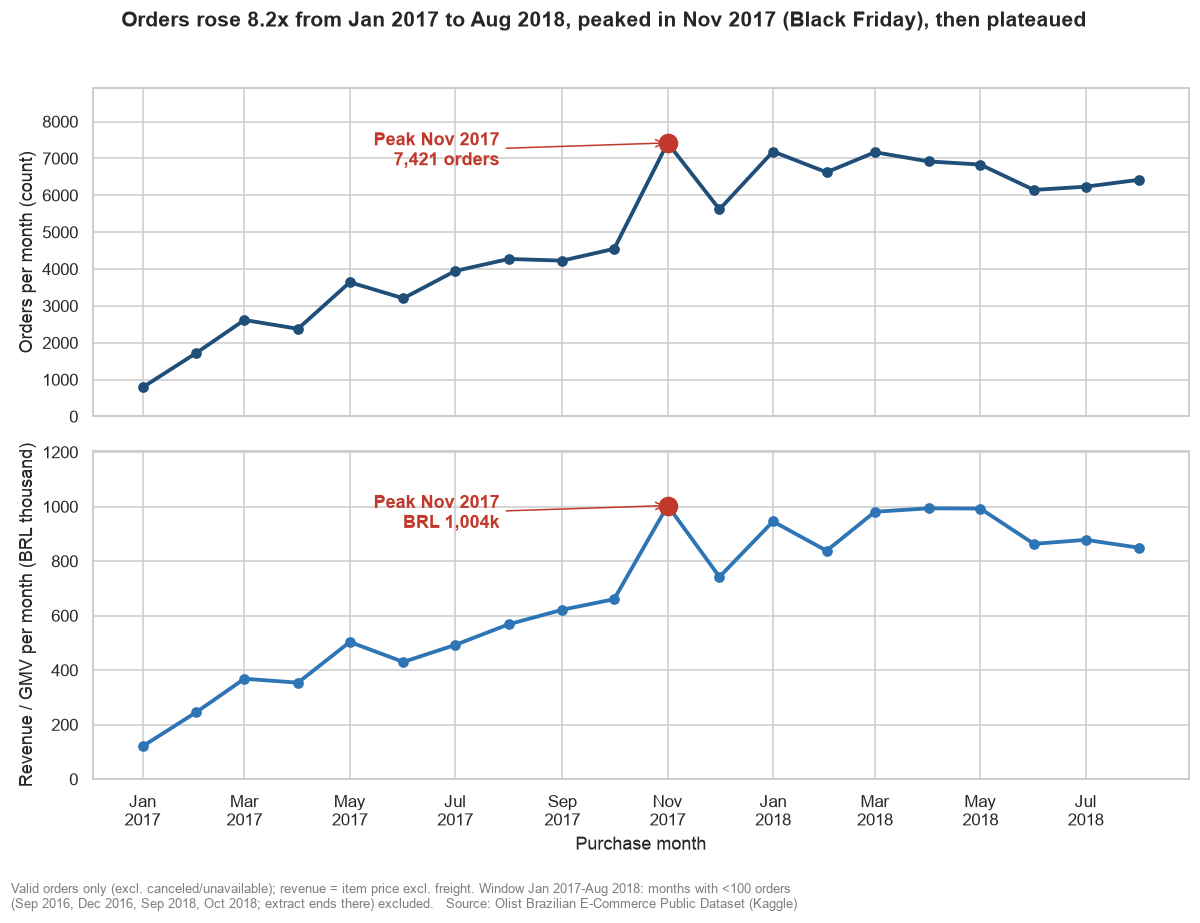

In [11]:
import matplotlib.pyplot as plt, matplotlib.dates as mdates
common.set_style()
months = pd.to_datetime(pdf["purchase_month"] + "-01")
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True, facecolor="white")
ax1.plot(months, pdf["orders"], color=common.PRIMARY, lw=2.5, marker="o")
ax1.set_ylabel("Orders per month (count)"); ax1.set_ylim(0, pdf["orders"].max() * 1.2)
ax2.plot(months, pdf["gmv"] / 1e3, color=common.ACCENT, lw=2.5, marker="o")
ax2.set_ylabel("Revenue / GMV per month (BRL thousand)"); ax2.set_ylim(0, pdf["gmv"].max() / 1e3 * 1.2)
pm = pd.to_datetime(peak.purchase_month + "-01")
ax1.scatter([pm], [peak.orders], s=140, color=common.ALERT, zorder=5)
ax1.annotate(f"Peak {pm:%b %Y}\n{int(peak.orders):,} orders", (pm, peak.orders), xytext=(-110, -5),
             textcoords="offset points", ha="right", va="center", color=common.ALERT, fontweight="bold",
             arrowprops=dict(arrowstyle="->", color=common.ALERT))
gm = pd.to_datetime(peak_gmv.purchase_month + "-01")
ax2.scatter([gm], [peak_gmv.gmv / 1e3], s=140, color=common.ALERT, zorder=5)
ax2.annotate(f"Peak {gm:%b %Y}\nBRL {peak_gmv.gmv/1e3:,.0f}k", (gm, peak_gmv.gmv / 1e3), xytext=(-110, -5),
             textcoords="offset points", ha="right", va="center", color=common.ALERT, fontweight="bold",
             arrowprops=dict(arrowstyle="->", color=common.ALERT))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y")); ax2.set_xlabel("Purchase month")
fig.suptitle(f"Orders rose {last.orders/first.orders:.1f}x from Jan 2017 to Aug 2018, peaked in "
             f"{pm:%b %Y} (Black Friday), then plateaued", fontsize=14, fontweight="bold", y=0.98)
fig.text(0.01, -0.01, "Valid orders only (excl. canceled/unavailable); revenue = item price excl. freight. "
         "Window Jan 2017-Aug 2018: months with <100 orders\n(Sep 2016, Dec 2016, Sep 2018, Oct 2018; extract ends there) excluded.   "
         + SOURCE, fontsize=8.5, color=common.GREY, ha="left", va="top")
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(FIG / "q1_monthly_trend.png", facecolor="white")
plt.show()

In [12]:
def ytd(year):
    m = pdf[(pdf["purchase_month"] >= f"{year}-01") & (pdf["purchase_month"] <= f"{year}-08")]
    return int(m["orders"].sum()), float(m["gmv"].sum())
o17, g17 = ytd(2017); o18, g18 = ytd(2018)
nov = pdf[pdf.purchase_month == "2017-11"].iloc[0]; dec = pdf[pdf.purchase_month == "2017-12"].iloc[0]
q1 = dict(peak_month=peak.purchase_month, peak_orders=int(peak.orders), peak_gmv=float(peak.gmv),
          nov_mom=float(nov.orders_mom_pct), dec_mom=float(dec.orders_mom_pct),
          peak_day=str(dpeak.d), peak_day_orders=int(dpeak.orders),
          growth=float(last.orders / first.orders), yoy_orders=(o18/o17-1)*100, yoy_gmv=(g18/g17-1)*100)
display(Markdown(f"""
**Result (Q1)**
- Peak month by orders and by GMV: **{q1['peak_month']}**, {q1['peak_orders']:,} orders and BRL {q1['peak_gmv']:,.2f} GMV.
- November 2017 grew {q1['nov_mom']:+.1f}% on October in orders, then December fell {q1['dec_mom']:+.1f}%. The busiest single day was {q1['peak_day']} ({q1['peak_day_orders']:,} orders).
- Orders grew {q1['growth']:.2f}x from Jan 2017 ({int(first.orders):,}) to Aug 2018 ({int(last.orders):,}); Jan-Aug 2018 vs Jan-Aug 2017: orders {q1['yoy_orders']:+.1f}%, GMV {q1['yoy_gmv']:+.1f}%.
- Growth flattened after Jan 2018 (about 6,100-7,200 orders a month).
"""))


**Result (Q1)**
- Peak month by orders and by GMV: **2017-11**, 7,421 orders and BRL 1,003,862.14 GMV.
- November 2017 grew +63.2% on October in orders, then December fell -24.3%. The busiest single day was 2017-11-24 (1,166 orders).
- Orders grew 8.16x from Jan 2017 (787) to Aug 2018 (6,421); Jan-Aug 2018 vs Jan-Aug 2017: orders +137.3%, GMV +138.3%.
- Growth flattened after Jan 2018 (about 6,100-7,200 orders a month).


## 6. Q2 — Which weekdays and hours do buyers purchase most?  *(Advanced visualization: heatmap)*
**Why it matters:** the busiest slots tell a marketplace when to schedule maintenance, run promotions and staff support.
Spark steps: one row per order (`distinct`), `groupBy` weekday and hour, **`pivot`** the 24 hours into columns to get a 7 x 24 matrix.
All months are used (we look for patterns, not trends).

In [13]:
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
# One row per order (an order has several item lines), valid orders only
ord_time = valid.select("order_id", "purchase_dow_num", "purchase_hour").distinct().cache()
total_orders_q2 = ord_time.count()

counts = ord_time.groupBy("purchase_dow_num", "purchase_hour").agg(F.count("*").alias("orders"))
matrix = (counts.groupBy("purchase_dow_num")
          .pivot("purchase_hour", list(range(24)))        # listing the values avoids an extra pass
          .sum("orders").na.fill(0).orderBy("purchase_dow_num"))
matrix.show(7, truncate=False)

m = matrix.toPandas().set_index("purchase_dow_num")       # only now: 7 x 24 to pandas
m.columns = [int(c) for c in m.columns]; m.index = DAYS
assert int(m.values.sum()) == total_orders_q2
day_tot, hour_tot = m.sum(axis=1), m.sum(axis=0)
pk_day, pk_hour = m.stack().idxmax()[0], int(m.stack().idxmax()[1]); pk_val = int(m.values.max())

+----------------+---+---+---+---+---+---+---+---+---+---+----+----+---+----+----+----+----+---+---+---+----+----+---+---+
|purchase_dow_num|0  |1  |2  |3  |4  |5  |6  |7  |8  |9  |10  |11  |12 |13  |14  |15  |16  |17 |18 |19 |20  |21  |22 |23 |
+----------------+---+---+---+---+---+---+---+---+---+---+----+----+---+----+----+----+----+---+---+---+----+----+---+---+
|1               |322|134|64 |36 |21 |22 |65 |159|475|765|1020|1068|961|1012|1082|1065|1076|974|915|933|1016|1103|982|708|
|2               |304|155|80 |28 |28 |24 |71 |219|515|853|950 |1040|889|1036|1106|1026|1074|956|868|909|970 |1017|955|685|
|3               |392|174|81 |31 |33 |26 |93 |210|508|817|1029|1046|912|1008|1039|971 |1024|958|837|833|892 |952 |872|612|
|4               |354|167|74 |39 |31 |28 |83 |217|497|750|970 |945 |963|968 |968 |916 |1066|893|776|814|829 |832 |850|541|
|5               |418|210|70 |48 |40 |35 |96 |204|493|758|942 |983 |843|989 |950 |969 |960 |806|716|772|730 |714 |695|507|
|6              

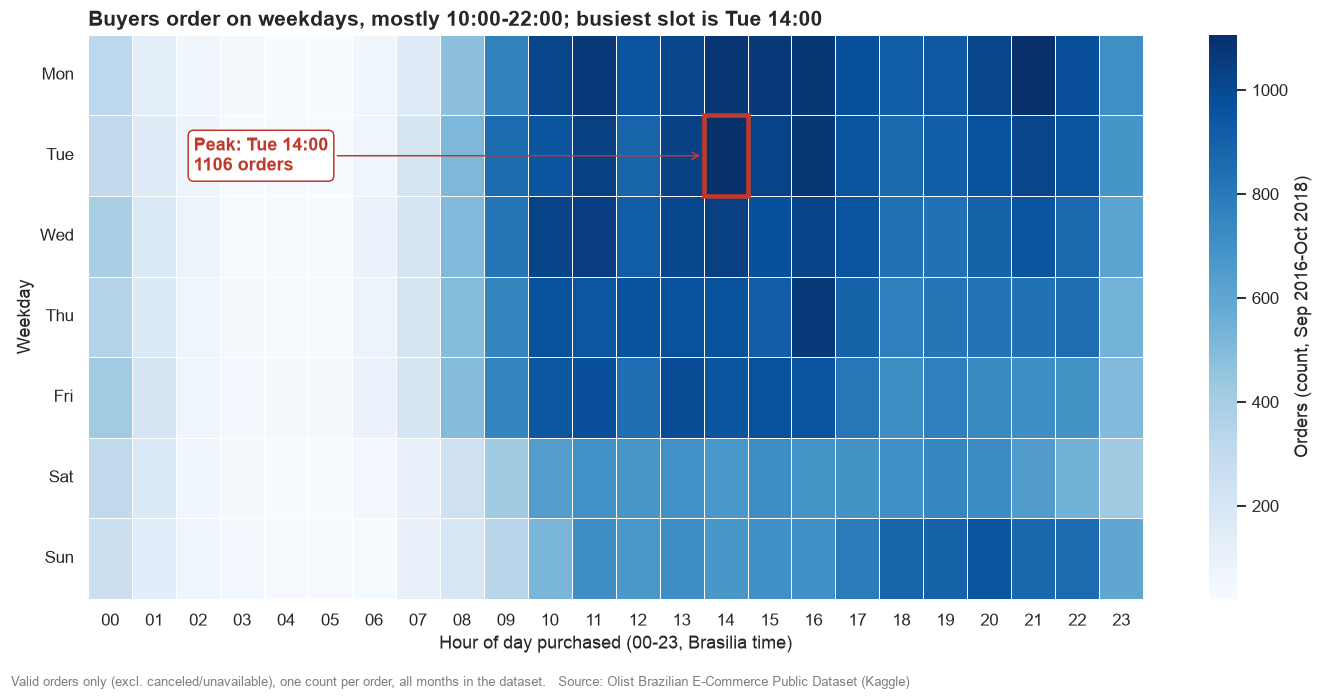

In [14]:
import seaborn as sns
from matplotlib.patches import Rectangle
fig, ax = plt.subplots(figsize=(13, 6.2), facecolor="white")
sns.heatmap(m, cmap="Blues", ax=ax, linewidths=0.6, linecolor="white",
            cbar_kws={"label": "Orders (count, Sep 2016-Oct 2018)"})
ax.set_xticklabels([f"{h:02d}" for h in range(24)], rotation=0); ax.set_yticklabels(DAYS, rotation=0)
ax.set_xlabel("Hour of day purchased (00-23, Brasilia time)"); ax.set_ylabel("Weekday"); ax.grid(False)
r, c = DAYS.index(pk_day), pk_hour
ax.add_patch(Rectangle((c, r), 1, 1, fill=False, edgecolor=common.ALERT, lw=3))
ax.annotate(f"Peak: {pk_day} {pk_hour:02d}:00\n{pk_val} orders", (c, r + 0.5), xytext=(2.4, r + 0.5),
            textcoords="data", color=common.ALERT, fontweight="bold", ha="left", va="center",
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=common.ALERT),
            arrowprops=dict(arrowstyle="->", color=common.ALERT))
ax.set_title(f"Buyers order on weekdays, mostly 10:00-22:00; busiest slot is {pk_day} {pk_hour:02d}:00", loc="left")
fig.text(0.01, -0.02, "Valid orders only (excl. canceled/unavailable), one count per order, all months in the dataset.   " + SOURCE,
         fontsize=8.5, color=common.GREY, ha="left")
fig.tight_layout(); fig.savefig(FIG / "q2_weekday_hour_heatmap.png", facecolor="white")
plt.show()

In [15]:
band = max(range(0, 22), key=lambda h: hour_tot.loc[h:h + 2].sum())
wk_share = day_tot[["Sat", "Sun"]].sum() / total_orders_q2 * 100
display(Markdown(f"""
**Result (Q2)**, over {total_orders_q2:,} valid orders:
- Busiest weekday **{day_tot.idxmax()}** ({day_tot.max()/total_orders_q2*100:.1f}% of orders); quietest **{day_tot.idxmin()}** ({day_tot.min()/total_orders_q2*100:.1f}%). Weekends together take {wk_share:.1f}%.
- Busiest hour **{int(hour_tot.idxmax()):02d}:00** ({int(hour_tot.max()):,} orders); busiest 3-hour band {band:02d}:00-{band+3:02d}:00 ({hour_tot.loc[band:band+2].sum()/total_orders_q2*100:.1f}%).
- Single busiest cell: **{pk_day} {pk_hour:02d}:00** with {pk_val:,} orders. Night (00:00-05:59) is only {hour_tot.loc[0:5].sum()/total_orders_q2*100:.1f}% of orders; 10:00-21:59 holds {hour_tot.loc[10:21].sum()/total_orders_q2*100:.1f}%.
"""))


**Result (Q2)**, over 98,199 valid orders:
- Busiest weekday **Mon** (16.3% of orders); quietest **Sat** (11.0%). Weekends together take 23.0%.
- Busiest hour **16:00** (6,594 orders); busiest 3-hour band 14:00-17:00 (19.8%).
- Single busiest cell: **Tue 14:00** with 1,106 orders. Night (00:00-05:59) is only 4.8% of orders; 10:00-21:59 holds 75.7%.


## 7. Q3 — Where are buyers and revenue concentrated?  *(Advanced visualization: geospatial map)*
**Why it matters:** demand concentration decides where to place warehouses, partner carriers and marketing spend.
Spark steps: aggregate valid orders per customer zip prefix and per state, then **join** to `geo_by_zip` (built from 1M raw geolocation rows)
for coordinates. A left join keeps zips without coordinates so we can count what the map misses.

In [16]:
# Aggregate per customer zip prefix: distinct orders and GMV
zip_agg = (valid.groupBy("customer_zip")
           .agg(F.countDistinct("order_id").alias("orders"), F.round(F.sum("price"), 2).alias("gmv")))
zip_geo = (zip_agg.join(geo_by_zip.select("zip_prefix", "lat", "lng"),
                        zip_agg.customer_zip == geo_by_zip.zip_prefix, "left")).cache()
total_orders = valid.select("order_id").distinct().count()
unmapped_orders = zip_geo.filter(F.col("lat").isNull()).agg(F.sum("orders")).first()[0] or 0
unmapped_zips = zip_geo.filter(F.col("lat").isNull()).count()
print(f"Orders that could not be geolocated: {unmapped_orders} of {total_orders:,} ({unmapped_zips} zip prefixes)")

# Aggregate per state; share of national orders and GMV; sellers per state
national_gmv = valid.agg(F.sum("price")).first()[0]
state_agg = (valid.groupBy("customer_state")
             .agg(F.countDistinct("order_id").alias("orders"), F.round(F.sum("price"), 2).alias("gmv"),
                  F.countDistinct("customer_unique_id").alias("customers"))
             .withColumn("gmv_share_pct", F.round(F.col("gmv") / national_gmv * 100, 2))
             .withColumn("orders_share_pct", F.round(F.col("orders") / total_orders * 100, 2))
             .withColumn("gmv_per_customer", F.round(F.col("gmv") / F.col("customers"), 2)))
sellers_state = sellers.groupBy("seller_state").agg(F.count("*").alias("sellers"))
state_agg = (state_agg.join(sellers_state, state_agg.customer_state == sellers_state.seller_state, "left")
             .drop("seller_state").fillna(0, subset=["sellers"]).orderBy(F.desc("gmv")).cache())
print("=== Top 10 states by GMV ===")
state_agg.show(10, truncate=False)

# Top cities
city_agg = (valid.groupBy("customer_city", "customer_state")
            .agg(F.countDistinct("order_id").alias("orders"), F.round(F.sum("price"), 2).alias("gmv"))
            .orderBy(F.desc("orders")))
print("=== Top 10 cities by orders ===")
city_agg.show(10, truncate=False)
n_sellers = sellers.count(); sellers_sp = sellers.filter(F.col("seller_state") == "SP").count()

states_pd = state_agg.toPandas().sort_values("gmv", ascending=False)
cities_pd = city_agg.limit(10).toPandas()
points = zip_geo.filter(F.col("lat").isNotNull()).toPandas()      # ~15k rows
print("Mapped zip prefixes:", len(points))

Orders that could not be geolocated: 274 of 98,199 (157 zip prefixes)


=== Top 10 states by GMV ===


+--------------+------+----------+---------+-------------+----------------+----------------+-------+
|customer_state|orders|gmv       |customers|gmv_share_pct|orders_share_pct|gmv_per_customer|sellers|
+--------------+------+----------+---------+-------------+----------------+----------------+-------+
|SP            |41125 |5163867.22|39747    |38.27        |41.88           |129.92          |1849   |
|RJ            |12697 |1811623.42|12241    |13.43        |12.93           |148.0           |171    |
|MG            |11496 |1573508.2 |11134    |11.66        |11.71           |141.32          |244    |
|RS            |5415  |742559.78 |5233     |5.5          |5.51            |141.9           |129    |
|PR            |4982  |676883.06 |4824     |5.02         |5.07            |140.32          |349    |
|SC            |3599  |518578.28 |3501     |3.84         |3.67            |148.12          |190    |
|BA            |3344  |507108.83 |3244     |3.76         |3.41            |156.32          

+---------------------+--------------+------+---------+
|customer_city        |customer_state|orders|gmv      |
+---------------------+--------------+------+---------+
|sao paulo            |SP            |15291 |1897019.8|
|rio de janeiro       |RJ            |6800  |986528.05|
|belo horizonte       |MG            |2737  |350760.93|
|brasilia             |DF            |2111  |300202.76|
|curitiba             |PR            |1502  |208008.66|
|campinas             |SP            |1422  |186925.85|
|porto alegre         |RS            |1369  |186788.31|
|salvador             |BA            |1234  |180735.72|
|guarulhos            |SP            |1167  |142578.38|
|sao bernardo do campo|SP            |921   |103930.01|
+---------------------+--------------+------+---------+
only showing top 10 rows


Mapped zip prefixes: 14807


**Interactive map.** To keep the notebook small we do the aggregation in Spark: coordinates are **rounded to 0.1 degree (about 11 km)** and
orders/GMV are summed per grid cell, so the map embeds only a few hundred circles instead of ~15,000 zip prefixes.
Circle area is proportional to GMV; hover for details.

In [17]:
import folium
# Spark: round coordinates to a 0.1-degree grid and sum per cell
grid = (zip_geo.filter(F.col("lat").isNotNull())
        .withColumn("glat", F.round("lat", 1)).withColumn("glng", F.round("lng", 1))
        .groupBy("glat", "glng").agg(F.sum("orders").alias("orders"), F.round(F.sum("gmv"), 0).alias("gmv"))
        .filter(F.col("orders") >= 5))
gpd = grid.toPandas()
print(f"{len(gpd):,} grid cells on the interactive map")

fmap = folium.Map(location=[-14.5, -51.0], zoom_start=4, tiles="OpenStreetMap")
for r in gpd.itertuples():
    folium.CircleMarker(location=[r.glat, r.glng], radius=min(3 + (r.gmv ** 0.5) / 40, 22),
                        color=common.PRIMARY, weight=0.5, fill=True, fill_color=common.ALERT, fill_opacity=0.5,
                        tooltip=f"{int(r.orders):,} orders, BRL {r.gmv:,.0f} GMV").add_to(fmap)
fmap.get_root().html.add_child(folium.Element(
    "<div style='position:fixed;bottom:8px;left:8px;z-index:9999;background:white;padding:4px 8px;font:12px Arial'>"
    "Buyer locations on a 0.1-degree grid (circle size = GMV, BRL). " + SOURCE + "</div>"))
fmap

1,898 grid cells on the interactive map


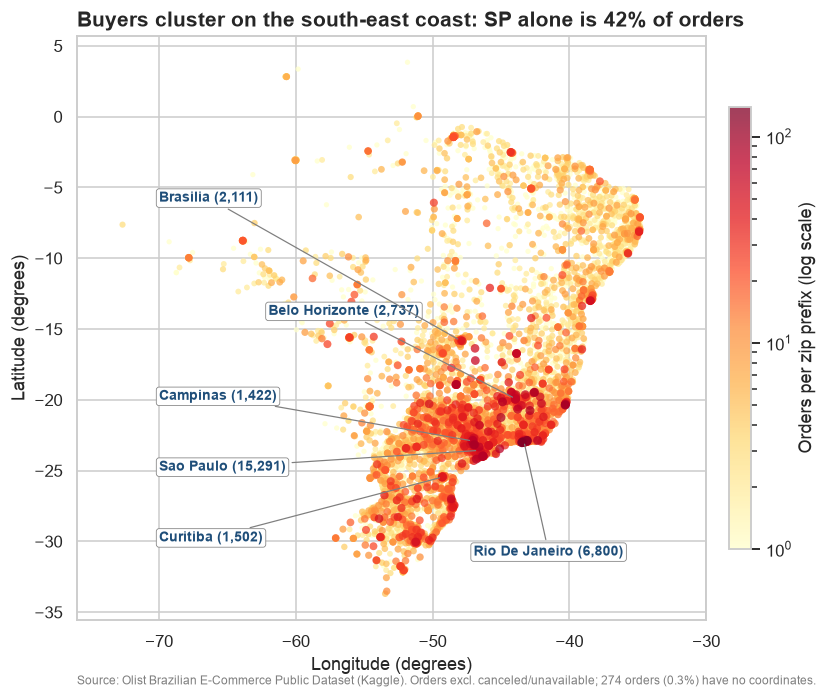

In [18]:
import numpy as np
from matplotlib.colors import LogNorm
sp_row = states_pd[states_pd.customer_state == "SP"].iloc[0]
fig, ax = plt.subplots(figsize=(9, 9.5), facecolor="white"); ax.set_facecolor("white")
p = points.sort_values("orders")
sc = ax.scatter(p.lng, p.lat, c=p.orders, s=8 + 6 * np.log1p(p.orders), cmap="YlOrRd",
                norm=LogNorm(vmin=1, vmax=p.orders.max()), alpha=0.75, edgecolor="none")
cb = fig.colorbar(sc, ax=ax, shrink=0.55, pad=0.03); cb.set_label("Orders per zip prefix (log scale)")
ax.set_aspect(1 / np.cos(np.radians(15)))
ax.set_xlabel("Longitude (degrees)"); ax.set_ylabel("Latitude (degrees)")
ax.set_title(f"Buyers cluster on the south-east coast: SP alone is {sp_row.orders_share_pct:.0f}% of orders", loc="left")
label_pos = {"sao paulo": (-70, -25), "rio de janeiro": (-47, -31), "belo horizonte": (-62, -14),
             "brasilia": (-70, -6), "curitiba": (-70, -30), "campinas": (-70, -20)}
zip_city = valid.select("customer_zip", "customer_city").distinct().toPandas()
for c in cities_pd.head(6).itertuples():
    sub = points.merge(zip_city, on="customer_zip"); sub = sub[sub.customer_city == c.customer_city]
    x, y = np.average(sub.lng, weights=sub.orders), np.average(sub.lat, weights=sub.orders)
    ax.annotate(f"{c.customer_city.title()} ({c.orders:,})", (x, y), xytext=label_pos.get(c.customer_city, (-70, -10)),
                fontsize=9, fontweight="bold", color=common.PRIMARY,
                arrowprops=dict(arrowstyle="-", color=common.GREY, lw=0.8),
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=common.GREY, lw=0.5))
ax.set_xlim(-76, -30)
ax.annotate(f"{SOURCE}. Orders excl. canceled/unavailable; {unmapped_orders:,} orders "
            f"({unmapped_orders / total_orders * 100:.1f}%) have no coordinates.",
            xy=(0, 0), xycoords="axes fraction", xytext=(0, -42), textcoords="offset points", fontsize=8, color=common.GREY)
fig.savefig(FIG / "q3_buyer_map.png"); plt.show()

In [19]:
top3 = states_pd.head(3); top3_o = states_pd.sort_values("orders", ascending=False).head(3)
display(Markdown(f"""
**Result (Q3)**, over {total_orders:,} valid orders and BRL {national_gmv:,.2f} GMV:
- **SP** has {int(sp_row.orders):,} orders = **{sp_row.orders_share_pct:.2f}%** of orders and {sp_row.gmv_share_pct:.2f}% of GMV.
- Top 3 states by GMV: {', '.join(top3.customer_state)} = {top3.gmv.sum()/national_gmv*100:.2f}% of GMV; top 3 by orders: {', '.join(top3_o.customer_state)} = {top3_o.orders.sum()/total_orders*100:.2f}% of orders.
- Top city: {cities_pd.customer_city[0].title()} ({int(cities_pd.orders[0]):,} orders, {cities_pd.orders[0]/total_orders*100:.2f}% of national orders).
- Sellers: {sellers_sp:,} of {n_sellers:,} ({sellers_sp/n_sellers*100:.2f}%) are in SP.
- Map coverage: {unmapped_orders:,} orders ({unmapped_orders/total_orders*100:.2f}%) in {unmapped_zips} zip prefixes could not be geolocated.
"""))


**Result (Q3)**, over 98,199 valid orders and BRL 13,494,400.74 GMV:
- **SP** has 41,125 orders = **41.88%** of orders and 38.27% of GMV.
- Top 3 states by GMV: SP, RJ, MG = 63.35% of GMV; top 3 by orders: SP, RJ, MG = 66.52% of orders.
- Top city: Sao Paulo (15,291 orders, 15.57% of national orders).
- Sellers: 1,849 of 3,095 (59.74%) are in SP.
- Map coverage: 274 orders (0.28%) in 157 zip prefixes could not be geolocated.


## 8. Q4 — Do late deliveries lower review scores?
**Why it matters:** reviews are a marketplace's trust currency. If late delivery destroys ratings, logistics quality is a growth lever.
Spark steps: `datediff` (done in section 3) gives `delay_days` = delivered date minus estimated date (positive = late). We **join** delivered orders
to reviews, compare on-time vs late, bucket the delay, and compute the correlation. Metrics are at **order level** (not item level).

In [20]:
# Delivered orders with a known outcome, plus buyer state
q4_orders = orders.filter((F.col("order_status") == "delivered") & F.col("is_late").isNotNull())
cust_state = customers.select("customer_id", "customer_state")
delivered = q4_orders.join(cust_state, "customer_id").cache()
n_delivered = delivered.count()
# Inner join to reviews (one row per order): orders without a review say nothing about satisfaction
scored = delivered.join(reviews.select("order_id", "review_score"), "order_id").cache()
n_scored = scored.count()
print(f"Delivered orders with a delivery outcome: {n_delivered:,}; with a review score: {n_scored:,}")

by_late = (scored.groupBy("is_late")
           .agg(F.count("*").alias("orders"), F.round(F.avg("review_score"), 3).alias("avg_score"),
                F.round(F.avg((F.col("review_score") == 1).cast("int")) * 100, 2).alias("pct_1star")))
print("On-time (false) vs late (true):"); by_late.show()
late_rows = {r["is_late"]: r for r in by_late.collect()}

# Delay buckets
d = F.col("delay_days")
bucket = (F.when(d < -7, "Early >7d").when(d < 0, "Early 1-7d").when(d == 0, "On time (0)")
          .when(d <= 3, "Late 1-3d").when(d <= 7, "Late 4-7d").when(d <= 14, "Late 8-14d").otherwise("Late >14d"))
order_of = {"Early >7d": 1, "Early 1-7d": 2, "On time (0)": 3, "Late 1-3d": 4, "Late 4-7d": 5, "Late 8-14d": 6, "Late >14d": 7}
bpd = (scored.withColumn("bucket", bucket).groupBy("bucket")
       .agg(F.count("*").alias("orders"), F.round(F.avg("review_score"), 3).alias("avg_score"),
            F.round(F.avg((F.col("review_score") == 1).cast("int")) * 100, 2).alias("pct_1star")).toPandas())
bpd["ord"] = bpd.bucket.map(order_of); bpd = bpd.sort_values("ord").reset_index(drop=True)
print(bpd.drop(columns="ord").to_string(index=False))

corr = scored.stat.corr("delay_days", "review_score")        # Pearson correlation computed by Spark
print("\nPearson correlation delay_days vs review_score:", round(corr, 4))

# Late rate per state (>= 500 delivered orders so rates are stable)
nat_late_rate = delivered.agg(F.avg(F.col("is_late").cast("int"))).first()[0] * 100
states = (delivered.groupBy("customer_state")
          .agg(F.count("*").alias("delivered_orders"),
               F.round(F.avg(F.col("is_late").cast("int")) * 100, 2).alias("late_rate_pct"),
               F.round(F.avg("delivery_days"), 1).alias("avg_delivery_days"))
          .filter(F.col("delivered_orders") >= 500).orderBy(F.desc("late_rate_pct")))
states.show(20)
spd = states.toPandas()

Delivered orders with a delivery outcome: 96,470; with a review score: 95,824
On-time (false) vs late (true):
+-------+------+---------+---------+
|is_late|orders|avg_score|pct_1star|
+-------+------+---------+---------+
|   true|  6381|     2.27|    53.77|
|  false| 89443|     4.29|     6.62|
+-------+------+---------+---------+



     bucket  orders  avg_score  pct_1star
  Early >7d   70929      4.317       6.47
 Early 1-7d   17234      4.201       7.07
On time (0)    1280      4.034       8.52
  Late 1-3d    1852      3.291      25.11
  Late 4-7d    1748      2.103      58.58
 Late 8-14d    1446      1.671      70.61
  Late >14d    1335      1.724      68.99

Pearson correlation delay_days vs review_score: -0.2674


+--------------+----------------+-------------+-----------------+
|customer_state|delivered_orders|late_rate_pct|avg_delivery_days|
+--------------+----------------+-------------+-----------------+
|            MA|             717|        17.43|             21.5|
|            CE|            1279|        13.76|             21.2|
|            BA|            3256|        12.16|             19.3|
|            RJ|           12350|        12.11|             15.2|
|            PA|             946|        11.21|             23.7|
|            ES|            1995|        10.73|             15.7|
|            PB|             517|        10.44|             20.4|
|            MS|             701|          9.7|             15.5|
|            PE|            1593|          9.6|             18.4|
|            SC|            3546|         8.21|             14.9|
|            GO|            1957|         6.54|             15.5|
|            RS|            5344|         6.08|             15.2|
|         

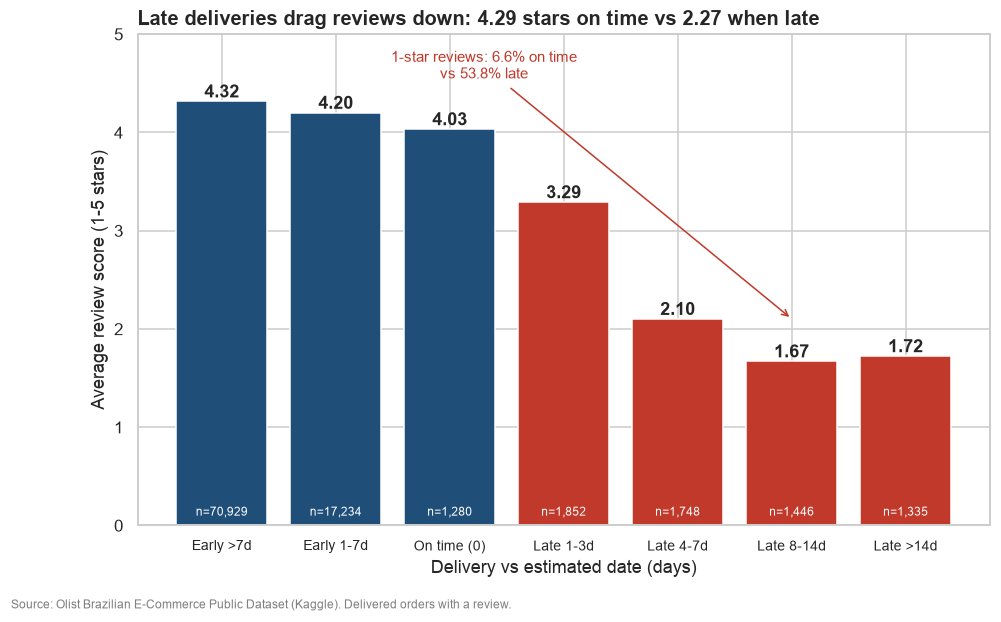

In [21]:
on, late = late_rows[False], late_rows[True]
fig, ax = plt.subplots(figsize=(10, 5.8), facecolor="white")
colors = [common.ALERT if b.startswith("Late") else common.PRIMARY for b in bpd.bucket]
bars = ax.bar(bpd.bucket, bpd.avg_score, color=colors)
for b, (s, n) in zip(bars, zip(bpd.avg_score, bpd.orders)):
    ax.text(b.get_x() + b.get_width() / 2, s + 0.04, f"{s:.2f}", ha="center", fontweight="bold")
    ax.text(b.get_x() + b.get_width() / 2, 0.1, f"n={n:,}", ha="center", color="white", fontsize=8)
ax.set_ylim(0, 5); ax.set_ylabel("Average review score (1-5 stars)"); ax.set_xlabel("Delivery vs estimated date (days)")
ax.set_title(f"Late deliveries drag reviews down: {on['avg_score']:.2f} stars on time vs {late['avg_score']:.2f} when late",
             loc="left", fontsize=13)
ax.tick_params(axis="x", labelsize=9)
ax.annotate(f"1-star reviews: {on['pct_1star']:.1f}% on time\nvs {late['pct_1star']:.1f}% late",
            xy=(5, bpd.avg_score[bpd.ord == 5].iloc[0]), xytext=(2.3, 4.55), fontsize=10, color=common.ALERT, ha="center",
            arrowprops=dict(arrowstyle="->", color=common.ALERT))
fig.text(0.01, -0.02, f"{SOURCE}. Delivered orders with a review.", fontsize=8, color=common.GREY)
fig.savefig(FIG / "q4_late_vs_score.png"); plt.show()

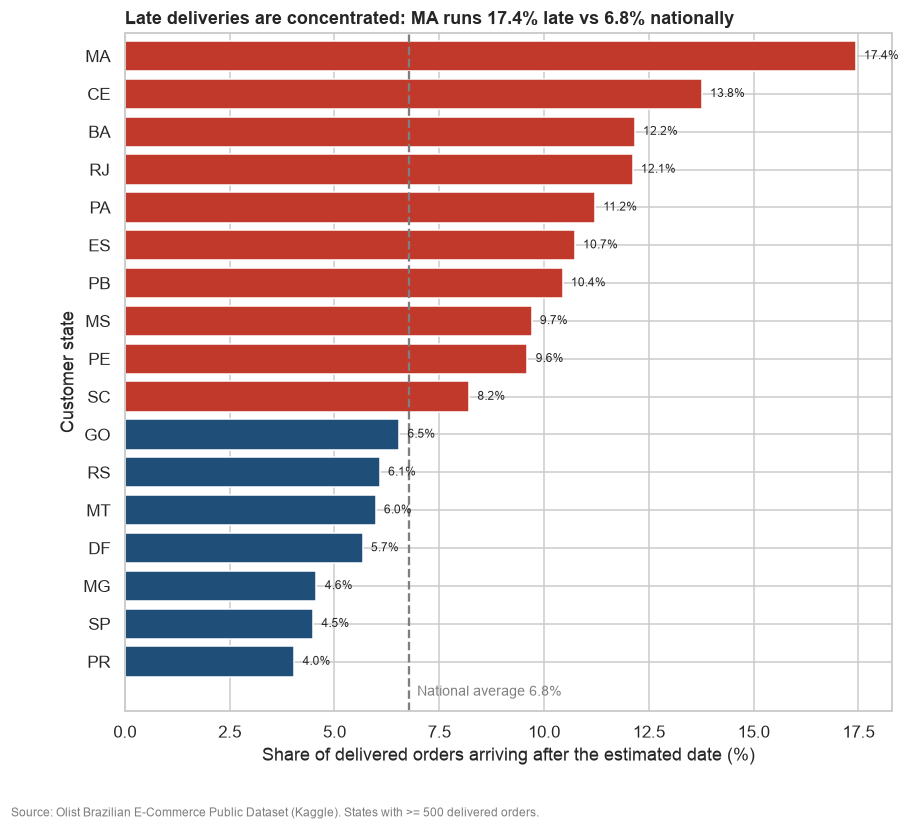

In [22]:
sp4 = spd.sort_values("late_rate_pct")
fig, ax = plt.subplots(figsize=(9, 8), facecolor="white")
cols = [common.ALERT if v > nat_late_rate else common.PRIMARY for v in sp4.late_rate_pct]
ax.barh(sp4.customer_state, sp4.late_rate_pct, color=cols)
for y, v in enumerate(sp4.late_rate_pct): ax.text(v + 0.2, y, f"{v:.1f}%", va="center", fontsize=8)
ax.axvline(nat_late_rate, color=common.GREY, ls="--")
ax.text(nat_late_rate + 0.2, -0.9, f"National average {nat_late_rate:.1f}%", color=common.GREY, fontsize=9)
ax.set_xlabel("Share of delivered orders arriving after the estimated date (%)"); ax.set_ylabel("Customer state")
worst = spd.iloc[0]
ax.set_title(f"Late deliveries are concentrated: {worst.customer_state} runs {worst.late_rate_pct:.1f}% late "
             f"vs {nat_late_rate:.1f}% nationally", loc="left", fontsize=12)
ax.set_ylim(-1.3, len(sp4) - 0.4)
fig.text(0.01, -0.01, f"{SOURCE}. States with >= 500 delivered orders.", fontsize=8, color=common.GREY)
fig.savefig(FIG / "q4_late_rate_by_state.png"); plt.show()

In [23]:
display(Markdown(f"""
**Result (Q4)**, {n_scored:,} delivered orders with a review:
- Average review score: **{on['avg_score']:.2f}** for {int(on['orders']):,} on-time orders vs **{late['avg_score']:.2f}** for {int(late['orders']):,} late orders (gap {on['avg_score']-late['avg_score']:.2f} stars).
- 1-star reviews: {on['pct_1star']:.2f}% on time vs {late['pct_1star']:.2f}% late. Correlation of delay days with score: {corr:.3f}.
- National late rate {nat_late_rate:.2f}%; worst state **{worst.customer_state}** at {worst.late_rate_pct:.2f}% (avg {worst.avg_delivery_days:.1f} days to deliver), best **{spd.iloc[-1].customer_state}** at {spd.iloc[-1].late_rate_pct:.2f}%.
- This is an association, not proof of causation (a late parcel may coincide with other problems).
"""))


**Result (Q4)**, 95,824 delivered orders with a review:
- Average review score: **4.29** for 89,443 on-time orders vs **2.27** for 6,381 late orders (gap 2.02 stars).
- 1-star reviews: 6.62% on time vs 53.77% late. Correlation of delay days with score: -0.267.
- National late rate 6.77%; worst state **MA** at 17.43% (avg 21.5 days to deliver), best **PR** at 4.04%.
- This is an association, not proof of causation (a late parcel may coincide with other problems).


## 9. Q5 — Which seller states ship to which buyer states?  *(Advanced visualization: network graph)*
**Why it matters:** the seller-state to buyer-state flow graph shows where the marketplace depends on one hub and where long, costly
shipping lanes exist. Spark steps: `order_lines` already joins orders, items, sellers and customers (a 4-table join); we `groupBy`
(seller_state, customer_state) and aggregate. States become **nodes**, flows become **directed edges** (drawn with `networkx`).
Note: an order with sellers in two states is counted once in each flow.

In [24]:
flows = (valid.groupBy("seller_state", "customer_state")
         .agg(F.countDistinct("order_id").alias("orders"), F.round(F.sum("price"), 2).alias("gmv"),
              F.round(F.avg("freight_value"), 2).alias("avg_freight"),
              F.round(F.avg("delivery_days"), 2).alias("avg_delivery_days"))
         .withColumn("intra", F.col("seller_state") == F.col("customer_state")).cache())
flows.orderBy(F.desc("orders")).show(10)

split = flows.groupBy("intra").agg(F.sum("orders").alias("orders")).toPandas().set_index("intra")
tot_orders = int(split["orders"].sum()); intra_orders = int(split.loc[True, "orders"]); inter_orders = int(split.loc[False, "orders"])

# Average freight per ITEM, same-state vs cross-state
fr = (valid.groupBy((F.col("seller_state") == F.col("customer_state")).alias("same"))
      .agg(F.avg("freight_value").alias("f")).toPandas().set_index("same")["f"])

# Out-degree = number of buyer states a seller state serves
out = (flows.groupBy("seller_state").agg(F.countDistinct("customer_state").alias("out_degree"),
                                         F.sum("orders").alias("out_orders"))
       .withColumn("out_share_pct", F.round(100 * F.col("out_orders") / tot_orders, 2)).orderBy(F.desc("out_orders")))
out.show(8)

# Node positions = mean lat/lng of each state's zip prefixes
cent = (geo_by_zip.groupBy("state").agg(F.avg("lat").alias("lat"), F.avg("lng").alias("lng"))
        .toPandas().set_index("state"))
flows_pd = flows.toPandas()
top10 = flows_pd.sort_values("orders", ascending=False).head(10)

+------------+--------------+------+----------+-----------+-----------------+-----+
|seller_state|customer_state|orders|       gmv|avg_freight|avg_delivery_days|intra|
+------------+--------------+------+----------+-----------+-----------------+-----+
|          SP|            SP| 31293|3585867.19|       13.2|             7.86| true|
|          SP|            RJ|  8421|1099866.81|      20.46|            16.03|false|
|          SP|            MG|  7565| 939581.74|      20.25|            12.23|false|
|          SP|            RS|  3661| 449317.64|       20.7|            15.95|false|
|          SP|            PR|  3167| 400412.64|       20.5|            12.72|false|
|          PR|            SP|  3010| 467590.39|      19.29|            11.06|false|
|          MG|            SP|  2620| 320115.74|       21.5|            10.86|false|
|          SP|            BA|  2380| 320971.09|      24.25|            19.68|false|
|          SP|            SC|  2364|  309145.9|      20.81|            15.77

+------------+----------+----------+-------------+
|seller_state|out_degree|out_orders|out_share_pct|
+------------+----------+----------+-------------+
|          SP|        27|     69854|        70.76|
|          MG|        27|      7880|         7.98|
|          PR|        27|      7647|         7.75|
|          RJ|        26|      4330|         4.39|
|          SC|        27|      3649|          3.7|
|          RS|        26|      1983|         2.01|
|          DF|        23|       821|         0.83|
|          BA|        27|       567|         0.57|
+------------+----------+----------+-------------+
only showing top 8 rows


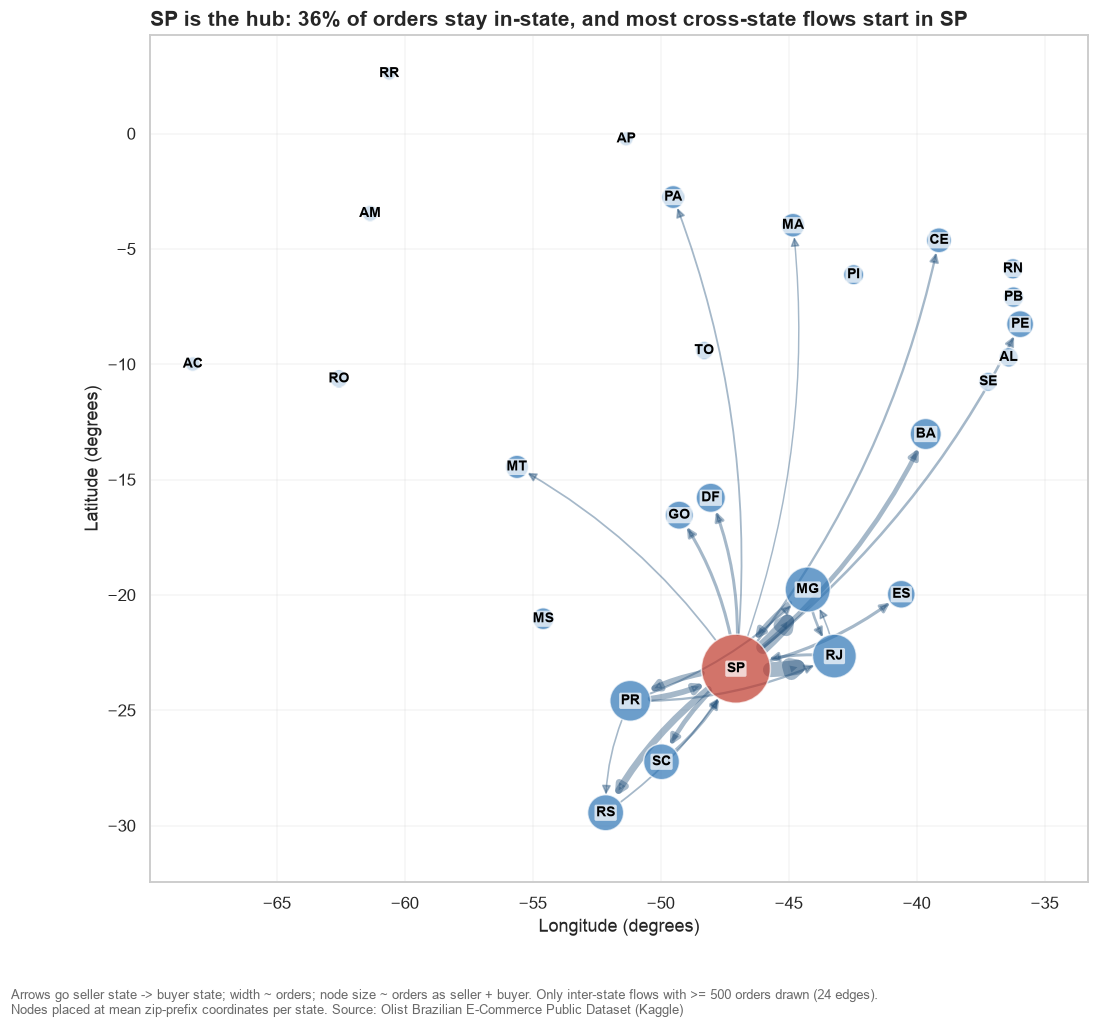

In [25]:
import networkx as nx
THRESH = 500                                     # draw only inter-state flows with >= 500 orders
inter = flows_pd[~flows_pd["intra"]]; shown = inter[inter["orders"] >= THRESH]
as_seller = flows_pd.groupby("seller_state")["orders"].sum()
as_buyer = flows_pd.groupby("customer_state")["orders"].sum()
size = as_seller.add(as_buyer, fill_value=0)

G = nx.DiGraph()
for s in cent.index:
    if s in size.index: G.add_node(s, pos=(cent.loc[s, "lng"], cent.loc[s, "lat"]))
for r in shown.itertuples(): G.add_edge(r.seller_state, r.customer_state, w=r.orders)
pos = nx.get_node_attributes(G, "pos")
NS = [40 + 6 * size[n] ** 0.5 for n in G]

fig, ax = plt.subplots(figsize=(11, 10), facecolor="white"); ax.set_facecolor("white")
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=NS, node_color=[common.ALERT if n == "SP" else common.ACCENT for n in G],
                       alpha=0.7, edgecolors="white")
nx.draw_networkx_edges(G, pos, ax=ax, width=[0.4 + G[u][v]["w"] / 900 for u, v in G.edges], edge_color=common.PRIMARY,
                       alpha=0.4, arrows=True, arrowsize=12, connectionstyle="arc3,rad=0.12", node_size=NS)
nx.draw_networkx_labels(G, pos, ax=ax, font_size=9, font_weight="bold", labels={n: n for n in G}, font_color="black",
                        bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.7))
ax.set_xlabel("Longitude (degrees)"); ax.set_ylabel("Latitude (degrees)")
ax.grid(alpha=0.2); ax.tick_params(labelbottom=True, labelleft=True)
ax.set_title(f"SP is the hub: {100*intra_orders/tot_orders:.0f}% of orders stay in-state, and most cross-state flows start in SP", loc="left")
fig.text(0.01, -0.01, f"Arrows go seller state -> buyer state; width ~ orders; node size ~ orders as seller + buyer. "
         f"Only inter-state flows with >= {THRESH} orders drawn ({len(shown)} edges).\n"
         "Nodes placed at mean zip-prefix coordinates per state. " + SOURCE, fontsize=8.5, color="dimgray")
fig.savefig(FIG / "q5_state_flow_network.png"); plt.show()

In [26]:
sp_out = shown[shown.seller_state == "SP"]["orders"].sum() / shown["orders"].sum()
display(Markdown(f"""
**Result (Q5)**, {tot_orders:,} flow-orders (an order counts once per seller-state/buyer-state pair):
- **{100*intra_orders/tot_orders:.2f}%** of flow-orders are intra-state ({intra_orders:,}); {100*inter_orders/tot_orders:.2f}% cross a state border ({inter_orders:,}).
- Average freight per item: BRL {fr[True]:.2f} within a state vs BRL {fr[False]:.2f} across states.
- The 10 biggest flows carry {100*top10.orders.sum()/tot_orders:.1f}% of flow-orders; the biggest is {top10.iloc[0].seller_state} -> {top10.iloc[0].customer_state} ({int(top10.iloc[0].orders):,} orders).
- Of the {len(shown)} drawn edges (>= {THRESH} orders), {100*sp_out:.2f}% of orders leave from SP.
"""))


**Result (Q5)**, 98,715 flow-orders (an order counts once per seller-state/buyer-state pair):
- **35.82%** of flow-orders are intra-state (35,356); 64.18% cross a state border (63,359).
- Average freight per item: BRL 13.45 within a state vs BRL 23.69 across states.
- The 10 biggest flows carry 66.9% of flow-orders; the biggest is SP -> SP (31,293 orders).
- Of the 24 drawn edges (>= 500 orders), 73.13% of orders leave from SP.


## 10. Q6 — Which product categories earn the most?
**Why it matters:** category concentration shows where seller supply and buyer demand are strongest, and which categories to promote or diversify.
Spark steps: category names were translated by a join in section 3; here `groupBy` category and a **`rank()` window** order them by GMV.
A second window partitioned by state finds each big state's leading category.

In [27]:
cat = (valid.groupBy("category_en")
       .agg(F.round(F.sum("price"), 2).alias("gmv"), F.countDistinct("order_id").alias("orders"),
            F.count("*").alias("items"), F.round(F.avg("price"), 2).alias("avg_price"),
            F.round(F.avg("review_score"), 2).alias("avg_review")).cache())
wr = Window.orderBy(F.desc("gmv"))                       # global rank window (~74 rows)
top10 = cat.withColumn("rank", F.rank().over(wr)).filter("rank <= 10").orderBy("rank")
top10.show(truncate=False)
top10_pd = top10.toPandas()
total_gmv = cat.agg(F.sum("gmv")).first()[0]
top10_share = 100 * top10_pd["gmv"].sum() / total_gmv
top10_pd["share_pct"] = 100 * top10_pd["gmv"] / total_gmv

# cross-check with the Spark SQL query of section 4
assert [r.category_en for r in sql_top_cat.collect()] == list(top10_pd.category_en), "SQL and DataFrame top-10 differ"
print("Spark SQL top-10 equals DataFrame top-10: OK")

# Partitioned window: best category WITHIN each of the 5 biggest buyer states
state_orders = valid.groupBy("customer_state").agg(F.countDistinct("order_id").alias("orders"))
big5 = [r.customer_state for r in state_orders.orderBy(F.desc("orders")).limit(5).collect()]
sc = (valid.filter(F.col("customer_state").isin(big5)).groupBy("customer_state", "category_en")
      .agg(F.round(F.sum("price"), 2).alias("gmv")))
ws = Window.partitionBy("customer_state").orderBy(F.desc("gmv"))
top_per_state = sc.withColumn("rank", F.rank().over(ws)).filter("rank = 1").orderBy(F.desc("gmv"))
top_per_state.show(truncate=False)
tps = top_per_state.toPandas()

+---------------------+----------+------+-----+---------+----------+----+
|category_en          |gmv       |orders|items|avg_price|avg_review|rank|
+---------------------+----------+------+-----+---------+----------+----+
|health_beauty        |1255695.13|8800  |9634 |130.34   |4.15      |1   |
|watches_gifts        |1198185.21|5604  |5970 |200.7    |4.03      |2   |
|bed_bath_table       |1035964.06|9399  |11097|93.36    |3.9       |3   |
|sports_leisure       |979740.92 |7673  |8590 |114.06   |4.12      |4   |
|computers_accessories|904322.02 |6654  |7781 |116.22   |3.95      |5   |
|furniture_decor      |727465.05 |6425  |8298 |87.67    |3.92      |6   |
|housewares           |626825.8  |5847  |6915 |90.65    |4.07      |7   |
|cool_stuff           |620770.49 |3616  |3779 |164.27   |4.16      |8   |
|auto                 |586585.73 |3872  |4204 |139.53   |4.08      |9   |
|garden_tools         |481009.94 |3505  |4328 |111.14   |4.06      |10  |
+---------------------+----------+----

Spark SQL top-10 equals DataFrame top-10: OK


+--------------+--------------+---------+----+
|customer_state|category_en   |gmv      |rank|
+--------------+--------------+---------+----+
|SP            |bed_bath_table|477794.2 |1   |
|RJ            |watches_gifts |183931.5 |1   |
|MG            |health_beauty |157433.32|1   |
|RS            |bed_bath_table|60270.74 |1   |
|PR            |watches_gifts |59859.04 |1   |
+--------------+--------------+---------+----+



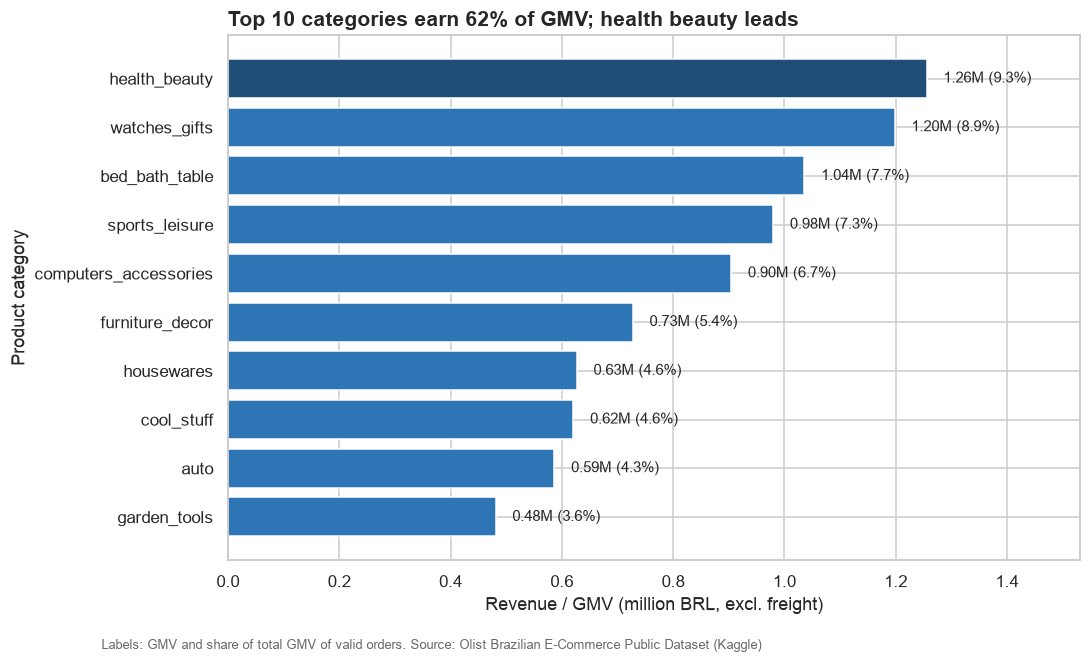

In [28]:
dd = top10_pd.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6.2), facecolor="white")
bars = ax.barh(dd["category_en"], dd["gmv"] / 1e6, color=[common.PRIMARY if i == 9 else common.ACCENT for i in range(10)])
for b, s in zip(bars, dd["share_pct"]):
    ax.text(b.get_width() + 0.03, b.get_y() + b.get_height() / 2, f"{b.get_width():.2f}M ({s:.1f}%)", va="center", fontsize=10)
ax.set_xlim(0, dd["gmv"].max() / 1e6 * 1.22)
ax.set_xlabel("Revenue / GMV (million BRL, excl. freight)"); ax.set_ylabel("Product category")
ax.set_title(f"Top 10 categories earn {top10_share:.0f}% of GMV; {top10_pd.category_en[0].replace('_',' ')} leads", loc="left")
fig.text(0.01, -0.02, "Labels: GMV and share of total GMV of valid orders. " + SOURCE, fontsize=8.5, color="dimgray")
fig.savefig(FIG / "q6_top_categories.png"); plt.show()

In [29]:
display(Markdown(f"""
**Result (Q6)**, {cat.count()} categories, total GMV BRL {total_gmv:,.2f}:
- Top 10 categories earn **{top10_share:.2f}%** of GMV.
- #1 **{top10_pd.category_en[0]}** (BRL {top10_pd.gmv[0]:,.2f}, {top10_pd.share_pct[0]:.2f}%), #2 {top10_pd.category_en[1]} ({top10_pd.share_pct[1]:.2f}%), #3 {top10_pd.category_en[2]} ({top10_pd.share_pct[2]:.2f}%).
- Leading category per big state: {', '.join(f'{r.customer_state}: {r.category_en}' for r in tps.itertuples())}.
"""))


**Result (Q6)**, 74 categories, total GMV BRL 13,494,400.74:
- Top 10 categories earn **62.37%** of GMV.
- #1 **health_beauty** (BRL 1,255,695.13, 9.31%), #2 watches_gifts (8.88%), #3 bed_bath_table (7.68%).
- Leading category per big state: SP: bed_bath_table, RJ: watches_gifts, MG: health_beauty, RS: bed_bath_table, PR: watches_gifts.


## 11. RDD vs DataFrame
The same question (orders per buyer state) answered two ways. The **DataFrame API** is declarative and optimised by Catalyst.
The **RDD API** (Resilient Distributed Dataset) is the low-level core: we write `map` -> `reduceByKey` -> sort ourselves and Spark
runs it as written (no optimiser, Python lambdas).

In [30]:
from operator import add
df = orders.join(customers, "customer_id").cache()      # one row per order + buyer state (all statuses)
df.count()                                              # action: fill the cache so timings are fair

t = time.time()
df_res = df.groupBy("customer_state").count().orderBy(F.desc("count"), "customer_state").take(5)
t_df = time.time() - t

t = time.time()
# select() the one column first: df.rdd turns every row into a Python object, so converting
# all ~20 columns (incl. timestamps) is very slow (~70 s here vs ~1 s for one column).
rdd_res = (df.select("customer_state").rdd
           .map(lambda r: (r.customer_state, 1))          # emit (key, 1) pairs
           .reduceByKey(add)                              # sum per key, combining within partitions first
           .sortBy(lambda kv: (-kv[1], kv[0]))            # descending count, tie-break by name
           .take(5))                                      # action: triggers the whole job
t_rdd = time.time() - t
assert [(r[0], r[1]) for r in df_res] == rdd_res, "RDD and DataFrame results differ!"
print("DataFrame:", [tuple(r) for r in df_res]); print("RDD      :", rdd_res)
print(f"Same answer. Timing (informational): DataFrame {t_df:.2f}s, RDD {t_rdd:.2f}s")

# Classic word-count style RDD example: items per category
cats = order_lines.select("category_en").rdd.map(lambda r: r[0])
print("Top categories by item count (RDD):", cats.map(lambda c: (c, 1)).reduceByKey(add).sortBy(lambda kv: -kv[1]).take(5))

DataFrame: [('SP', 41746), ('RJ', 12852), ('MG', 11635), ('RS', 5466), ('PR', 5045)]
RDD      : [('SP', 41746), ('RJ', 12852), ('MG', 11635), ('RS', 5466), ('PR', 5045)]
Same answer. Timing (informational): DataFrame 0.13s, RDD 1.27s


Top categories by item count (RDD): [('bed_bath_table', 11115), ('health_beauty', 9670), ('sports_leisure', 8641), ('furniture_decor', 8334), ('computers_accessories', 7827)]


In [31]:
# Partitions = units of parallelism; repartition() shuffles data into a new number of partitions
n_before = df.rdd.getNumPartitions()
n_after = df.repartition(4).rdd.getNumPartitions()
print(f"partitions before = {n_before}, after repartition(4) = {n_after}")

partitions before = 1, after repartition(4) = 4


### Transformations vs actions

| Kind | Examples used in this notebook | Behaviour |
|---|---|---|
| **Narrow transformation** | `select`, `filter`, `withColumn`, `map` | lazy; each output partition depends on one input partition, no shuffle |
| **Wide transformation** | `groupBy`/`agg`, `join`, `pivot`, window functions, `reduceByKey`, `repartition` | lazy; needs a **shuffle** (data moves between partitions) |
| **Action** | `count`, `show`, `take`, `collect`, `toPandas`, `write.parquet` | triggers a job that executes the whole DAG |
| **Caching** | `cache()` | lazy marker; the data is stored after the first action that computes it |

## 12. Insights and Recommendations

### Key findings

1. **Q1 - Growth was steep and Black Friday was the biggest spike.** Monthly orders rose from 787 (Jan 2017) to 6,421 (Aug 2018), about 8.16x. November 2017 peaked at 7,421 orders (BRL 1,003,862), up 63.2% on October, with a single-day peak on 2017-11-24 (1,166 orders), then fell 24.3% in December. *So what:* a marketplace must provision capacity and promotions for a few extreme days, not the average month. Black Friday is a plausible cause, not proven.
2. **Q2 - Buyers shop on weekdays, in the afternoon and evening.** Monday is busiest (16.3% of orders) and Saturday quietest (11.0%); 14:00-17:00 alone holds 19.8% of orders and the single busiest slot is Tuesday 14:00 (1,106 orders). *So what:* send campaigns and push notifications just before these windows, and schedule heavy batch jobs overnight (00:00-06:00 is only 4.8% of orders).
3. **Q3 - Demand is concentrated in a few states.** SP, RJ and MG together give 63.35% of GMV; SP alone has 41.88% of orders and the city of Sao Paulo 15.57%. Buyers in RJ spend more per customer (BRL 148.00) than SP (BRL 129.92). *So what:* growth is mostly about deepening the south-east, while the remaining states are a smaller, harder-to-serve opportunity.
4. **Q4 - Late delivery goes with much worse reviews.** On-time orders average 4.29 stars versus 2.27 for late ones, and 53.77% of late orders get 1 star versus 6.62% on time. The national late rate is 6.77% but MA reaches 17.43% (avg 21.5 days) while SP is 4.49%. *So what:* delivery promises directly shape seller ratings and repeat trust. This is correlation: late orders may also differ in other ways (product, seller), and the overall delay-versus-score correlation is only -0.27.
5. **Q5 - SP is the supply hub, so most orders cross state lines.** 64.18% of order flows are inter-state and only 35.82% stay in-state; SP sellers originate 70.76% of all flows. Average freight is BRL 23.69 inter-state versus BRL 13.45 intra-state, and SP to BA takes 19.68 days versus 7.86 for SP to SP. *So what:* distance costs buyers money and time, so geographic seller mix matters. Multi-seller orders are counted once per state pair.
6. **Q6 - A few categories earn most of the money.** The top 10 of 74 categories earn 62.37% of GMV; health_beauty leads (9.31%), then watches_gifts (8.88%). Review scores differ (e.g. bed_bath_table 3.90, cool_stuff 4.16). *So what:* focus merchandising on the top 10 but monitor quality, since big categories are not automatically the best-rated.

### Connecting the findings

- **Distance chain:** 59.74% of sellers (1,849 of 3,095) are in SP (Q3), so most orders ship from SP (Q5). Far-away buyers wait longer (BA 19.3 days, MA 21.5, CE 21.2) and are late more often (MA 17.43%, CE 13.76%, BA 12.16%) (Q4), and late orders score about 2 stars lower.
- **Supply gap:** BA has only 19 sellers for 3,344 orders, so almost everything must be shipped in from elsewhere (Q3, Q5).
- **Peak load meets fulfilment:** the November 2017 surge (Q1) hit a network where inter-state shipping is already slow (Q5). Whether the surge itself raised lateness is not tested here.

### Recommendations

| Recommendation | Evidence (numbers) | Who acts | Expected impact |
|---|---|---|---|
| Plan capacity, stock and promotions before Black Friday | Nov 2017: 7,421 orders, +63.2% MoM, then -24.3% in Dec | Marketplace, sellers | Fewer stock-outs and slowdowns at peak; smoother December |
| Time campaigns and notifications to 14:00-17:00 on weekdays and Sunday evenings | 14:00-17:00 = 19.8% of orders; Mon 16.3% vs Sat 11.0% | Marketplace | Better response per message; batch jobs moved to quiet hours |
| Recruit sellers or open fulfilment hubs outside SP, starting with BA, CE, MA and RJ | SP sellers = 70.76% of flows; inter-state freight BRL 23.69 vs 13.45 | Marketplace, logistics | Shorter shipping, lower freight, fewer late orders |
| Show realistic delivery estimates and send proactive delay messages in high-late-rate states | MA 17.43%, CE 13.76%, BA 12.16% late vs SP 4.49% | Marketplace, logistics | Fewer unpleasant surprises, so fewer 1-star reviews |
| Track on-time delivery as a seller-quality metric | Late orders: 2.27 stars vs 4.29; 1-star 53.77% vs 6.62% | Marketplace, sellers | Ratings better reflect seller service; early warning on weak carriers |
| Prioritise the top-10 categories but watch their review scores | Top 10 = 62.37% of GMV; bed_bath_table 3.90 stars | Marketplace, sellers | Revenue focus without letting quality slip in large categories |

### How this maps to eBay's Big Data stack (FA1 link)

- **Storage and compute:** at eBay scale the same PySpark code would run on a YARN cluster reading from HDFS instead of local CSVs. Only the paths and the cluster size change.
- **Parquet:** columnar files let Spark read only the needed columns, which suits wide event tables far better than CSV.
- **Streaming:** the late-delivery logic (promised date versus now) could run in Spark Structured Streaming to raise real-time delay alerts.
- **Serving:** results such as per-state late rates or seller scores could be pushed to HBase or Cassandra for low-latency lookups on the website.

### Limitations

- Olist is a stand-in: Brazilian data from 2016-2018, so patterns (SP hub, Black Friday) will not transfer exactly to eBay.
- All links shown are correlations, not proven causes.
- Thin months (2016-09, 2016-12, 2018-09, 2018-10) were excluded from the Q1 trend.
- Q5 counts a multi-seller order once per seller-state and buyer-state pair, and delivery metrics cover delivered orders only.

## 13. Spark concepts used

| Concept | Where in this notebook |
|---|---|
| SparkSession, local mode, parallelism | Section 1 |
| Explicit schema (`StructType`) on CSV read, `multiLine` | Section 2 |
| Actions (`count`, `show`, `take`, `collect`, `toPandas`) | Sections 2-11 |
| `filter`, `select`, `withColumn`, `dropDuplicates`, `coalesce` | Section 3 |
| Joins (left, left_semi, inner) and the no-fan-out check | Section 3, Q4, Q5 |
| Window functions: `row_number` (dedup), `lag` (MoM growth), `rank` (top categories) | Section 3, Q1, Q6 |
| Lazy evaluation, DAG, Catalyst plan (`explain()`) | Section 3 |
| `cache()` / persistence | Sections 2, 3, Q2-Q6 |
| Parquet write/read (columnar, schema preserved) | Section 3 |
| Spark SQL and temporary views | Section 4, Q1, Q6 |
| `groupBy` / `agg` / `countDistinct` | Q1-Q6 |
| `pivot` | Q2 |
| `datediff`, `date_format`, `hour`, `dayofweek` | Section 3, Q1, Q2, Q4 |
| Statistics (`stat.corr`) | Q4 |
| Spark-side reduction before plotting (grid aggregation for the map) | Q3 |
| RDD API (`map`, `reduceByKey`, `sortBy`), partitions, `repartition` | Section 11 |
| Visualization: time series, heatmap, geospatial map, network graph, bar charts | Q1, Q2, Q3, Q5, Q4/Q6 |

## 14. Limitations and References

### Limitations
- **Stand-in data:** Olist is not eBay; patterns (Brazil, 2016-2018, one platform's logistics model) may not transfer to eBay or to today.
- **Short period:** the data covers Sep 2016 - Oct 2018; thin months (Sep 2016, Dec 2016, Sep 2018, Oct 2018, fewer than 100 orders each) are excluded from the Q1 trend, so seasonality over several years cannot be assessed.
- **Correlation is not causation:** late delivery goes with low scores (Q4), but we did not control for product type, price or seller.
- **Q5 double counting:** an order with sellers in several states counts once in each seller-state/buyer-state flow.
- **Geography:** coordinates are zip-prefix averages, not exact addresses; a small share of orders (about 0.3%) has no coordinates.
- **Scale:** Spark ran in local mode on one laptop; the code is cluster-ready but we did not test cluster performance.

### References
- Olist, *Brazilian E-Commerce Public Dataset by Olist*, Kaggle: https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce
- Apache Spark documentation: https://spark.apache.org/docs/latest/

In [32]:
print(f"Notebook compute time so far: {(time.time()-NB_T0)/60:.1f} min")
shutil.rmtree(TMP, ignore_errors=True)       # remove the scratch Parquet folder
spark.stop()

Notebook compute time so far: 0.8 min
